# Logistic Regression — v2

**Van Nguyen Thanh Dat — 3124411067 · Nhóm 10 · UCI 697**

## Mục tiêu thí nghiệm

Kiểm tra liệu `class_weight: balanced` có giúp Logistic Regression nhận diện
thêm sinh viên thuộc lớp `Enrolled` và cải thiện Macro F1 hay không.

V2 dùng cùng 36 đặc trưng, bộ tiền xử lý và 5 fold đã lưu như v1.
Tham số huấn luyện duy nhất thay đổi là `class_weight`, từ `null` sang `balanced`.

Macro F1 trung bình trên 5 fold là chỉ số so sánh chính. Phân tích OOF
đối chiếu Precision và Recall của `Enrolled`, đồng thời theo dõi Recall
của `Dropout`. Tập Test chưa được chấm trong thí nghiệm này.

## 1. Môi trường và đường dẫn

Tự tìm final/ từ vị trí notebook; không dùng đường dẫn riêng của tác giả.

In [20]:
import sys

print(sys.executable)
print(sys.version.split()[0])

c:\Users\Dat\.conda\envs\student-dropout\python.exe
3.12.16


In [21]:
from pathlib import Path
import sys
import os
import json
import hashlib
import importlib.util
import platform
import pandas as pd
import numpy as np
import yaml
from IPython.display import display, Image

candidates = [
    p
    for base in [Path.cwd(), *Path.cwd().parents]
    for p in [base, base / 'final']
]
FINAL = next(
    p.resolve()
    for p in candidates
    if (p / 'src/data.py').is_file() and (p / 'data/raw/data.csv').is_file()
)
sys.path.insert(0, str(FINAL))
os.environ.setdefault('MPLCONFIGDIR', str(FINAL.parent / '.venv/matplotlib-cache'))
from src.data import load_student_data, load_splits, LABELS
from src.features import make_preprocessor
from src.evaluate import run_cv_experiment

print('Python:', platform.python_version())
print('Project:', FINAL.name)

Python: 3.12.16
Project: final


## 2. Dữ liệu và nhãn

Loader kiểm chứng checksum/schema, giữ nguyên thứ tự dòng và tách Target riêng ở y; không sửa CSV nguồn.

In [22]:
X, y = load_student_data()
assert X.shape == (4424, 36) and 'Target' not in X.columns
source = json.loads((FINAL / 'data/source_manifest.json').read_text(encoding='utf-8'))
print('X:', X.shape, '| y:', y.shape)
print('SHA-256:', source['csv_sha256'])
display(y.value_counts().reindex(LABELS).rename_axis('Nhãn').to_frame('Số mẫu'))

X: (4424, 36) | y: (4424,)
SHA-256: 3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae


,Số mẫu
Nhãn,
Dropout,1421
Enrolled,794
Graduate,2209


## 3. Bộ chia chung và tiền xử lý

80/20 stratify, seed 42; CV 5-fold trên Train. Nạp file chỉ số có sẵn, không chia riêng. Vị trí trong folds tương đối với X_train.

LR dùng 18 cột StandardScaler, 10 cột One-Hot và 8 cột nhị phân giữ nguyên. Tạo Pipeline mới trong mỗi fold; chỉ fit encoder/scaler trên phần Train của fold. Không imputation, loại ngoại lệ, resampling hoặc thêm đặc trưng cả v1 và v2 đều không điền giá trị thiếu, loại ngoại lệ, lấy mẫu hoặc thêm đặc trưng.

In [23]:
train_ids, test_ids, folds, split_manifest = load_splits()
X_train, y_train = X.iloc[train_ids], y.iloc[train_ids]
assert not set(train_ids) & set(test_ids)
print('Train:', len(train_ids), '| Test:', len(test_ids), '| CV:', len(folds))
fold_summary = []
for number, (fit, valid) in enumerate(folds, 1):
    row = {
        'Fold': number,
        'Fit': len(fit),
        'Validation': len(valid),
    }
    row.update(
        {
            label: int((y_train.iloc[valid] == label).sum())
            for label in LABELS
        }
    )
    fold_summary.append(row)
display(pd.DataFrame(fold_summary).set_index('Fold'))

preprocessor = make_preprocessor()
assert not hasattr(preprocessor, 'transformers_')
print('Preprocessor LR mới tạo chưa fit.')

Train: 3539 | Test: 885 | CV: 5


,Fit,Validation,Dropout,Enrolled,Graduate
Fold,,,,,
1,2831,708,227,127,354
2,2831,708,227,127,354
3,2831,708,228,127,353
4,2831,708,228,127,353
5,2832,707,227,127,353


Preprocessor LR mới tạo chưa fit.


## 4. Cấu hình và model factory

L2, C=1, lbfgs, max_iter=2000, tol=1e-4, class_weight=balanced. Không tuning. Factory được nạp từ train.py của LR, không viết lại thuật toán trong notebook.

In [24]:
MODEL_ID = "m05_logistic_regression"
MODEL_VERSION = "v2"

model_dir = FINAL / "models" / MODEL_ID / MODEL_VERSION
spec = importlib.util.spec_from_file_location(
    f"train_{MODEL_ID}_{MODEL_VERSION}",
    model_dir / "train.py",
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)
config = yaml.safe_load((model_dir / 'config.yaml').read_text(encoding='utf-8'))
assert config["model_id"] == MODEL_ID
assert config["version"] == MODEL_VERSION
print('Tham số:', config['params'])
print(module.make_model(config))

Tham số: {'C': 1.0, 'l1_ratio': 0.0, 'solver': 'lbfgs', 'max_iter': 2000, 'tol': 0.0001, 'class_weight': 'balanced', 'fit_intercept': True, 'random_state': 42}
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['Previous qualification '
                                                   '(grade)',
                                                   'Admission grade',
                                                   'Age at enrollment',
                                                   'Unemployment rate',
                                                   'Inflation rate', 'GDP',
                                                   'Curricular units 1st sem '
                                                   '(credited)',
                                                   'Curricular units 1st sem '
                                                   '(enrolled)',
           

## 5. Đọc run đã có hoặc huấn luyện mới

`RUN_NEW_EXPERIMENT = False`: chỉ đọc kết quả Logistic Regression v2 đã huấn luyện. Đổi thành True để fit 5 fold và fit lại toàn Train; tạo run mới cho riêng model này. Không tạo run của mô hình khác. Không dự đoán hoặc đánh giá Test.

Không chạy nhiều notebook cùng ghi experiments/results.csv đồng thời trong một checkout.

In [25]:
RUN_NEW_EXPERIMENT = False

if RUN_NEW_EXPERIMENT:
    run_path = run_cv_experiment(model_dir / "config.yaml", module.make_model)
else:
    run_path = (
        FINAL
        / "experiments"
        / "runs"
        / "m05_logistic_regression_v2_20261104T075442_d8fcba3b"
    )
    print("Đọc kết quả từ run đã lưu.")

assert run_path.is_dir(), f"Không tìm thấy thư mục run: {run_path}"
print("Run:", run_path.name)

Đọc kết quả từ run đã lưu.
Run: m05_logistic_regression_v2_20261104T075442_d8fcba3b


## 6. Kết quả CV và độ ổn định

Trung bình 5 fold, std ddof=0. Theo dõi Macro-F1, Accuracy, Recall Dropout và gap Train–Validation; không gọi các số này là Test.

,Macro-F1 CV,Std (ddof=0),Accuracy CV,Recall Dropout CV,Train Macro-F1,Gap Train–Validation
Model,,,,,,
m05_logistic_regression,0.7067,0.0143,0.7485,0.7361,0.7691,0.0625


,fold,train_f1_macro,valid_f1_macro,valid_accuracy,valid_recall_Dropout,gap_f1_macro
0,1,0.7666,0.7193,0.7542,0.7004,0.0473
1,2,0.7691,0.7279,0.7684,0.7445,0.0412
2,3,0.7692,0.6997,0.7458,0.7500,0.0695
3,4,0.7634,0.6945,0.7444,0.7675,0.0690
4,5,0.7774,0.6920,0.7298,0.7181,0.0854


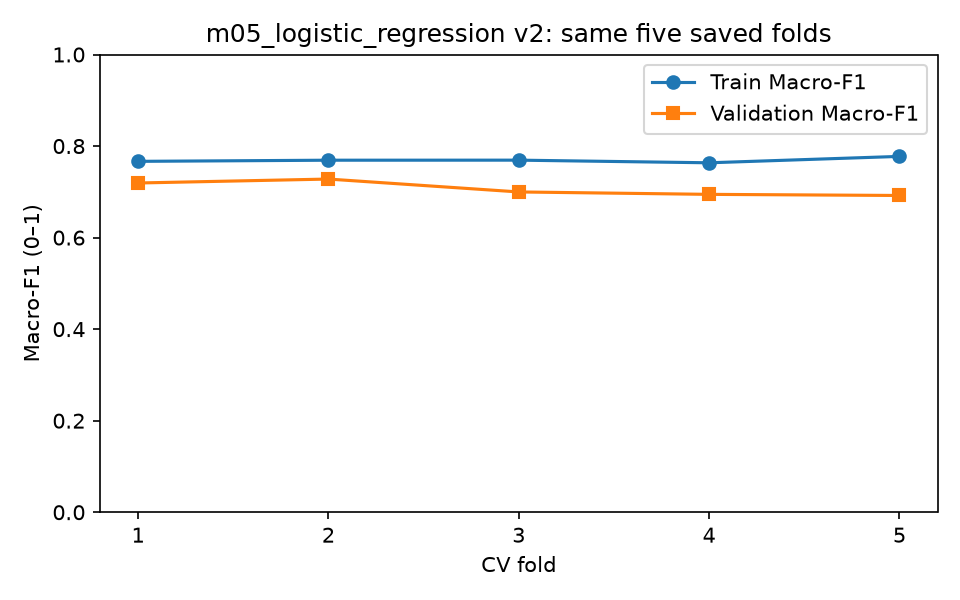

In [26]:
recorded_config = yaml.safe_load((run_path / 'config.yaml').read_text(encoding='utf-8'))
assert recorded_config == config, (
    'Config khác run; cần chọn đúng version hoặc chạy mới.'
)
tracking = json.loads((run_path / 'tracking.json').read_text(encoding='utf-8'))
assert tracking['status'] == 'complete'
metrics = json.loads((run_path / 'metrics.json').read_text(encoding='utf-8'))
assert metrics['model_id'] == MODEL_ID and not metrics['test_scored_this_run']
cv = metrics['cv']
display(
    pd.DataFrame(
        [
            {
                'Model': MODEL_ID,
                'Macro-F1 CV': cv['valid_f1_macro_mean'],
                'Std (ddof=0)': cv['valid_f1_macro_std'],
                'Accuracy CV': cv['valid_accuracy_mean'],
                'Recall Dropout CV': cv['valid_recall_Dropout_mean'],
                'Train Macro-F1': cv['train_f1_macro_mean'],
                'Gap Train–Validation': cv['gap_f1_macro_mean'],
            }
        ]
    )
    .set_index('Model')
    .round(4)
)
display(
    pd.read_csv(run_path / 'fold_metrics.csv')[
        [
            'fold',
            'train_f1_macro',
            'valid_f1_macro',
            'valid_accuracy',
            'valid_recall_Dropout',
            'gap_f1_macro',
        ]
    ].round(4)
)
display(Image(filename=str(run_path / 'figures/cv_macro_f1.png')))

Trên cùng 5 fold, Logistic Regression v2 (`class_weight: balanced`)
đạt Macro F1 trung bình 0,7067 ± 0,0143, tăng khoảng 0,0069 so với
v1 (0,6997 ± 0,0099). Điểm giữa các fold dao động nhiều hơn ở v2.

Accuracy trung bình giảm từ 77,54% xuống 74,85%. Recall của lớp
Dropout giảm từ 77,48% xuống 73,61%. Vì vậy, dù Macro F1 tăng nhẹ,
v2 phát hiện được ít sinh viên bỏ học hơn trên các fold validation.

## 7. OOF, lỗi từng lớp và confusion matrix

Mỗi sinh viên Train có một dự đoán từ model không học mẫu đó trong fold. OOF gộp khác CV mean; ma trận có hàng là nhãn thật và cột là dự đoán.

,precision,recall,f1-score,support
label,,,,
Dropout,0.8150,0.7361,0.7736,1137.0
Enrolled,0.4542,0.5937,0.5147,635.0
Graduate,0.8532,0.8121,0.8321,1767.0


Macro-F1 OOF: 0.7068


,Dropout,Enrolled,Graduate
true_label,,,
Dropout,837,204,96
Enrolled,107,377,151
Graduate,83,249,1435


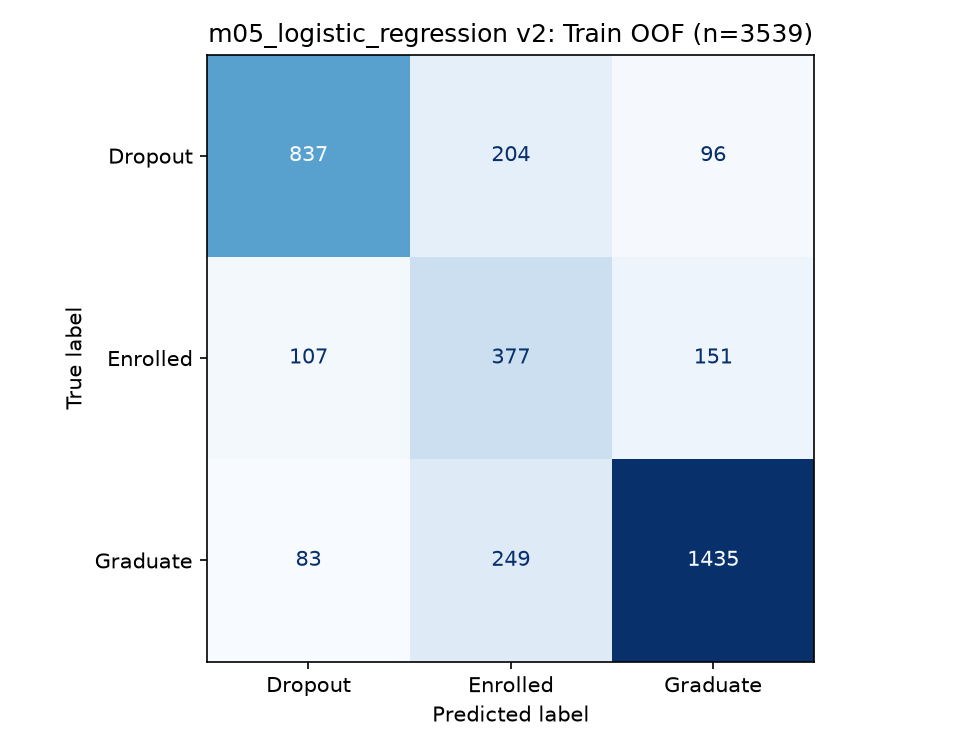

Dropout bị bỏ sót: 300
Cảnh báo Dropout nhầm: 190


In [27]:
classes = pd.read_csv(run_path / 'class_metrics_oof.csv')
display(classes.set_index('label').round(4))
print('Macro-F1 OOF:', round(metrics['oof']['f1_macro'], 4))
cm = pd.read_csv(run_path / 'confusion_matrix.csv', index_col=0)
display(cm)
display(Image(filename=str(run_path / 'figures/confusion_matrix.png')))
print('Dropout bị bỏ sót:', int(cm.loc['Dropout'].sum() - cm.loc['Dropout', 'Dropout']))
print('Cảnh báo Dropout nhầm:', int(cm['Dropout'].sum() - cm.loc['Dropout', 'Dropout']))

Trên dự đoán OOF của tập Train, Logistic Regression v2 nhận diện đúng
377/635 sinh viên Enrolled, so với 240/635 ở v1. Recall tăng từ 37,8%
lên 59,4%, còn Precision giảm từ khoảng 57,4% xuống 45,4%. Như vậy,
v2 tìm được thêm 137 sinh viên Enrolled, nhưng tỷ lệ dự đoán đúng
trong số các mẫu được gán nhãn Enrolled giảm.

Với lớp Dropout, v2 nhận diện đúng 837/1.137 sinh viên, ít hơn 44
so với v1 (881/1.137). Đây là điểm đánh đổi cần cân nhắc khi mục tiêu
của đồ án là phát hiện sinh viên có nguy cơ bỏ học.

## 8. Truy vết, giới hạn và kết luận

- Run: `m05_logistic_regression_v2_20261104T075442_d8fcba3b`.
- Cấu hình của lần chạy được lưu trong `config.yaml` của run.
  `git_info.json` ghi commit gốc và mã SHA-256 của các tệp dùng khi chạy.
- V2 dùng cùng 5 fold với v1. Macro F1 CV tăng nhẹ và Recall OOF của
  Enrolled tăng, trong khi Precision OOF của Enrolled và Recall CV
  của Dropout giảm. Khi chọn phiên bản, cần cân nhắc mức giảm khả năng
  phát hiện sinh viên bỏ học bên cạnh mức tăng Macro F1.
- Run v2 chưa chấm tập Test. Bộ đặc trưng có kết quả học kỳ 2, nên
  kết quả này chưa đánh giá khả năng dự đoán ngay khi nhập học.

In [28]:
info = json.loads((run_path / 'git_info.json').read_text(encoding='utf-8'))
changed = [
    name
    for name, digest in info['source_sha256'].items()
    if hashlib.sha256((FINAL / name).read_bytes()).hexdigest() != digest
]
print('Source hiện tại khớp lúc chạy:', not changed)
if changed:
    print('File đã thay đổi:', changed)
verify_path = run_path / 'verification.json'
if verify_path.exists():
    print(
        'Kiểm chứng độc lập:',
        len(json.loads(verify_path.read_text(encoding='utf-8'))['checks_passed']),
        'mục đạt',
    )
else:
    print('Run mới chưa có biên bản kiểm chứng độc lập.')
print('Bằng chứng:', run_path.relative_to(FINAL).as_posix())
print('W&B:', tracking['wandb_status'])

Source hiện tại khớp lúc chạy: True
Run mới chưa có biên bản kiểm chứng độc lập.
Bằng chứng: experiments/runs/m05_logistic_regression_v2_20261104T075442_d8fcba3b
W&B: not_configured
